# Laboratorio 6 ( con PyTorch del Laboratorio 2)

**Estudiante:** Espinoza Chiri Soledad Griselda  
**Materia:** SIS420
**Carrera:** Ing. de Sistemas
### Dataset: Flood Prediction Dataset (Kaggle)

Conjunto de datos sintético diseñado para predecir la probabilidad de inundación. Contiene diversas características ambientales, geográficas y de gestión que influyen en el riesgo de inundación.

**Dataset utilizado:** [Flood Prediction Dataset](https://www.kaggle.com/datasets/naiyakhalid/flood-prediction-dataset)

- **n = 20** variables independientes (características que describen factores de riesgo de inundación)
- **m = 50 000** ejemplos (filas)
- **Variable objetivo (y):** `FloodProbability` — probabilidad estimada de inundación (valor continuo entre 0 y 1)



In [1]:
# Conectando / vinculando nuestro drive
from google.colab import drive
drive.mount('/content/drive')

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from matplotlib import pyplot
from sklearn.metrics import mean_squared_error, r2_score


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print('Dispositivo utilizado:', device)

Mounted at /content/drive
Dispositivo utilizado: cpu


# Cargar Dataset

In [2]:
# Cargar el dataset desde Google Drive con Pandas
ruta_csv = '/content/drive/MyDrive/SIS420/flood.csv'

df = pd.read_csv(ruta_csv)

print('Dimensiones del dataset (filas, columnas):', df.shape)
df.head()

Dimensiones del dataset (filas, columnas): (50000, 21)


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0.450
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0.475
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,0.515
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,0.520
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0.475


In [3]:
# Informacion general del dataset: tipos de dato y valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   MonsoonIntensity                 50000 non-null  int64  
 1   TopographyDrainage               50000 non-null  int64  
 2   RiverManagement                  50000 non-null  int64  
 3   Deforestation                    50000 non-null  int64  
 4   Urbanization                     50000 non-null  int64  
 5   ClimateChange                    50000 non-null  int64  
 6   DamsQuality                      50000 non-null  int64  
 7   Siltation                        50000 non-null  int64  
 8   AgriculturalPractices            50000 non-null  int64  
 9   Encroachments                    50000 non-null  int64  
 10  IneffectiveDisasterPreparedness  50000 non-null  int64  
 11  DrainageSystems                  50000 non-null  int64  
 12  CoastalVulnerabili

In [4]:
# Estadisticas descriptivas de cada columna
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MonsoonIntensity,50000.0,4.99148,2.236834,0.000,3.000,5.0,6.000,16.000
TopographyDrainage,50000.0,4.98410,2.246488,0.000,3.000,5.0,6.000,18.000
RiverManagement,50000.0,5.01594,2.231310,0.000,3.000,5.0,6.000,16.000
Deforestation,50000.0,5.00848,2.222743,0.000,3.000,5.0,6.000,17.000
Urbanization,50000.0,4.98906,2.243159,0.000,3.000,5.0,6.000,17.000
ClimateChange,50000.0,4.98834,2.226761,0.000,3.000,5.0,6.000,17.000
DamsQuality,50000.0,5.01536,2.245000,0.000,3.000,5.0,6.000,16.000
Siltation,50000.0,4.98860,2.232642,0.000,3.000,5.0,6.000,16.000
AgriculturalPractices,50000.0,5.00612,2.234588,0.000,3.000,5.0,6.000,16.000
Encroachments,50000.0,5.00638,2.241633,0.000,3.000,5.0,6.000,18.000


## Preprocesamiento de datos

1. Verificar y eliminar valores nulos (`NaN`).
2. Verificar y eliminar filas duplicadas.
3. Separar la variable objetivo (`FloodProbability`) del resto de caracteristicas.
4. Convertir el `DataFrame` a arreglos `numpy` como paso previo a construir los tensores de `PyTorch`.

In [5]:
# Verificar valores nulos por columna
print('Valores nulos por columna:')
print(df.isnull().sum())
print('\nTotal de valores nulos en el dataset:', df.isnull().sum().sum())

Valores nulos por columna:
MonsoonIntensity                   0
TopographyDrainage                 0
RiverManagement                    0
Deforestation                      0
Urbanization                       0
ClimateChange                      0
DamsQuality                        0
Siltation                          0
AgriculturalPractices              0
Encroachments                      0
IneffectiveDisasterPreparedness    0
DrainageSystems                    0
CoastalVulnerability               0
Landslides                         0
Watersheds                         0
DeterioratingInfrastructure        0
PopulationScore                    0
WetlandLoss                        0
InadequatePlanning                 0
PoliticalFactors                   0
FloodProbability                   0
dtype: int64

Total de valores nulos en el dataset: 0


In [6]:
# Eliminar nulos (si existieran) y filas duplicadas
filas_antes = df.shape[0]

df = df.dropna()
df = df.drop_duplicates()

filas_despues = df.shape[0]
print(f'Filas antes del preprocesamiento: {filas_antes}')
print(f'Filas despues del preprocesamiento: {filas_despues}')
print(f'Filas eliminadas: {filas_antes - filas_despues}')

Filas antes del preprocesamiento: 50000
Filas despues del preprocesamiento: 50000
Filas eliminadas: 0


In [7]:
# Separar variable objetivo (y) de las caracteristicas (X)
columna_objetivo = 'FloodProbability'

X_df = df.drop(columns=[columna_objetivo])
y_df = df[columna_objetivo]

print('Numero de caracteristicas (n):', X_df.shape[1])
print('Numero de ejemplos (m):', X_df.shape[0])
print('\nCaracteristicas utilizadas:')
print(list(X_df.columns))

Numero de caracteristicas (n): 20
Numero de ejemplos (m): 50000

Caracteristicas utilizadas:
['MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors']


In [8]:
# Conversion a arreglos numpy
X = X_df.to_numpy(dtype=float)
y = y_df.to_numpy(dtype=float)

m = y.size
n = X.shape[1]

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (50000, 20)
y shape: (50000,)


## División en conjunto de entrenamiento y prueba

Se separa el dataset en un **80% para entrenamiento** y un **20% para prueba**, usando un mezclado aleatorio con semilla fija para que el experimento sea reproducible.

In [9]:
np.random.seed(42)

indices = np.random.permutation(m)
frac_train = 0.8
corte = int(m * frac_train)

idx_train = indices[:corte]
idx_test = indices[corte:]

X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

m_train = y_train.size
m_test = y_test.size

print('Ejemplos de entrenamiento:', m_train)
print('Ejemplos de prueba:', m_test)

Ejemplos de entrenamiento: 40000
Ejemplos de prueba: 10000


## Normalización de características

Se normalizan restando la media y dividiendo entre la desviacion estandar. **Importante:** la media y la desviacion estandar se calculan **unicamente con el conjunto de entrenamiento**, y esos mismos valores se usan para normalizar el conjunto de prueba.

In [10]:
def featureNormalize(X):
    '''
    Normaliza las caracteristicas en X. Retorna una version normalizada de X donde
    el valor de la media de cada caracteristica es 0 y la desviacion estandar es 1.
    '''
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma


# Se calcula mu y sigma solo con el conjunto de entrenamiento
X_train_norm, mu, sigma = featureNormalize(X_train)

# El conjunto de prueba se normaliza con la misma mu y sigma del entrenamiento
X_test_norm = (X_test - mu) / sigma

print('Media calculada (mu):')
print(mu)
print('\nDesviacion estandar calculada (sigma):')
print(sigma)

Media calculada (mu):
[4.994175 4.984025 5.016875 5.0022   4.98535  4.98405  5.016375 4.988925
 5.004275 5.004275 5.005875 5.010325 5.0018   4.97885  4.985075 4.99195
 4.98345  5.003675 4.99475  4.9841  ]

Desviacion estandar calculada (sigma):
[2.23937292 2.24032806 2.23042378 2.22610538 2.24265142 2.22674552
 2.24106155 2.23130059 2.23236572 2.24330264 2.22372221 2.23954647
 2.25137664 2.23084125 2.2324879  2.23679127 2.23550354 2.23654007
 2.23428343 2.25139894]


## Objetos Dataset y DataLoader

Se define una clase que hereda de `torch.utils.data.Dataset` para encapsular las 20 caracteristicas normalizadas y la variable objetivo, tal como se muestra en el cuadernillo `03_pytorch_datasets`. Luego se crean los `DataLoader` de entrenamiento y de prueba.

In [11]:
class DatasetFlood(torch.utils.data.Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, ix):
        return self.X[ix], self.y[ix]


train_dataset = DatasetFlood(X_train_norm, y_train)
test_dataset = DatasetFlood(X_test_norm, y_test)

print('Ejemplos de entrenamiento:', len(train_dataset))
print('Ejemplos de prueba:', len(test_dataset))

Ejemplos de entrenamiento: 40000
Ejemplos de prueba: 10000


In [12]:
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256, shuffle=False)

x_batch, y_batch = next(iter(train_loader))
print('Forma del batch de X:', x_batch.shape)
print('Forma del batch de y:', y_batch.shape)

Forma del batch de X: torch.Size([256, 20])
Forma del batch de y: torch.Size([256, 1])


## Definición del modelo

El modelo de regresión lineal multivariable se define como una capa `nn.Linear(n, 1)` dentro de una clase que hereda de `nn.Module`. Los `n = 20` pesos de esta capa mas el `bias` corresponden al vector `theta` del Laboratorio 2.

In [13]:
class RegresionLinealMultiple(nn.Module):

    def __init__(self, n_features):
        super(RegresionLinealMultiple, self).__init__()
        self.fc = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.fc(x)


model = RegresionLinealMultiple(n).to(device)
model

RegresionLinealMultiple(
  (fc): Linear(in_features=20, out_features=1, bias=True)
)

## Objetos de costo y optimización — selección de alpha

Se prueban varios valores de `alpha` (`lr`) entrenando pocas epocas con cada uno, para observar cual logra que la funcion de costo converja de forma rapida y estable, sin divergir.

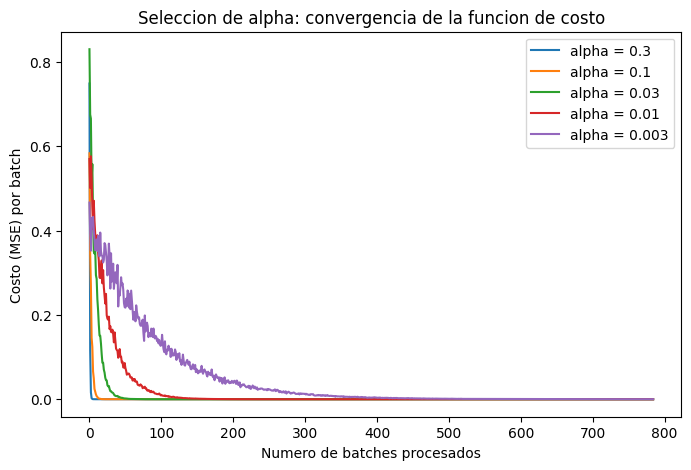

In [14]:
criterion = nn.MSELoss()

alphas_a_probar = [0.3, 0.1, 0.03, 0.01, 0.003]
epocas_prueba = 5

pyplot.figure(figsize=(8, 5))

for alpha_prueba in alphas_a_probar:
    modelo_prueba = RegresionLinealMultiple(n).to(device)
    optimizer_prueba = torch.optim.SGD(modelo_prueba.parameters(), lr=alpha_prueba)
    J_hist_prueba = []

    for epoch in range(epocas_prueba):
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            outputs = modelo_prueba(x_batch)
            loss = criterion(outputs, y_batch)

            optimizer_prueba.zero_grad()
            loss.backward()
            optimizer_prueba.step()

            J_hist_prueba.append(loss.item())

    pyplot.plot(J_hist_prueba, lw=1.5, label=f'alpha = {alpha_prueba}')

pyplot.xlabel('Numero de batches procesados')
pyplot.ylabel('Costo (MSE) por batch')
pyplot.title('Seleccion de alpha: convergencia de la funcion de costo')
pyplot.legend()
pyplot.show()

In [15]:
alpha = 0.3
num_epochs = 30

model = RegresionLinealMultiple(n).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=alpha)

historial_costo = []

model.train()
for epoch in range(num_epochs):
    costo_epoch = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        outputs = model(x_batch)
        loss = criterion(outputs, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        costo_epoch += loss.item() * x_batch.size(0)

    costo_epoch /= len(train_dataset)
    historial_costo.append(costo_epoch)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {costo_epoch:.6f}')

print('\nCosto final de entrenamiento:', historial_costo[-1])

Epoch [5/30], Loss: 0.000000
Epoch [10/30], Loss: 0.000000
Epoch [15/30], Loss: 0.000000
Epoch [20/30], Loss: 0.000000
Epoch [25/30], Loss: 0.000000
Epoch [30/30], Loss: 0.000000

Costo final de entrenamiento: 2.679634292235278e-16


### Gráfica de la función de costo vs. número de épocas



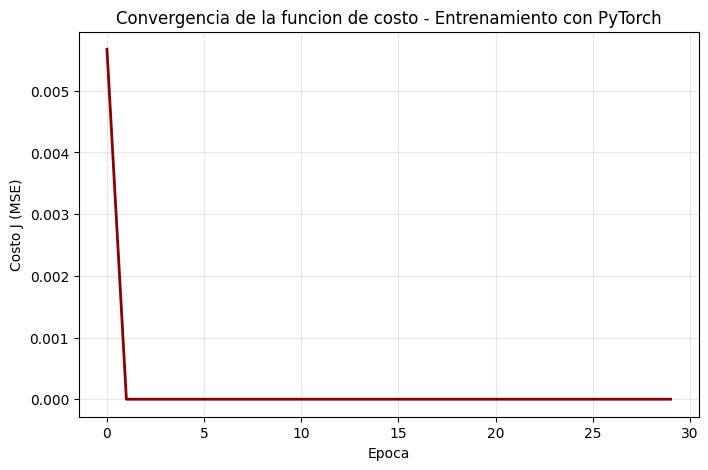

Costo inicial (epoca 1): 0.005672
Costo final (epoca 30): 0.000000


In [16]:
pyplot.figure(figsize=(8, 5))
pyplot.plot(historial_costo, lw=2, color='darkred')
pyplot.xlabel('Epoca')
pyplot.ylabel('Costo J (MSE)')
pyplot.title('Convergencia de la funcion de costo - Entrenamiento con PyTorch')
pyplot.grid(alpha=0.3)
pyplot.show()

print(f'Costo inicial (epoca 1): {historial_costo[0]:.6f}')
print(f'Costo final (epoca {num_epochs}): {historial_costo[-1]:.6f}')

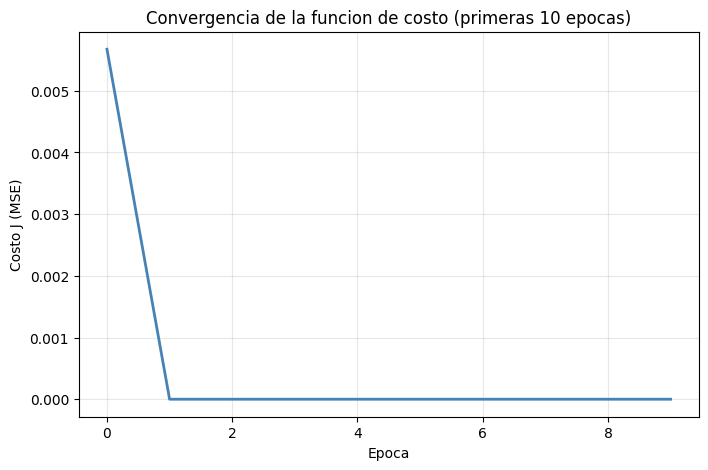

In [17]:
pyplot.figure(figsize=(8, 5))
pyplot.plot(historial_costo[:10], lw=2, color='steelblue')
pyplot.xlabel('Epoca')
pyplot.ylabel('Costo J (MSE)')
pyplot.title('Convergencia de la funcion de costo (primeras 10 epocas)')
pyplot.grid(alpha=0.3)
pyplot.show()

## Guardando los pesos del modelo

Se guarda el `state_dict` del modelo entrenado y se recarga para comprobar que funciona correctamente.

In [18]:
PATH = '/content/drive/MyDrive/SIS420/lab2_checkpoint.pt'
torch.save(model.state_dict(), PATH)
print('Pesos guardados en:', PATH)

modelo_cargado = RegresionLinealMultiple(n).to(device)
modelo_cargado.load_state_dict(torch.load(PATH, map_location=device))
modelo_cargado.eval()

Pesos guardados en: /content/drive/MyDrive/SIS420/lab2_checkpoint.pt


RegresionLinealMultiple(
  (fc): Linear(in_features=20, out_features=1, bias=True)
)

## Evaluación del modelo

Se evalua el modelo entrenado sobre el conjunto de **prueba** , utilizando el costo `J` y las metricas de `sklearn.metrics`: **MSE**, **RMSE** y **R^2**.

In [19]:
def evaluar(modelo, loader):
    modelo.eval()
    y_real_lista, y_pred_lista = [], []
    costo_total, n_ejemplos = 0.0, 0

    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            outputs = modelo(x_batch)
            loss = criterion(outputs, y_batch)

            costo_total += loss.item() * x_batch.size(0)
            n_ejemplos += x_batch.size(0)

            y_real_lista.append(y_batch.cpu().numpy())
            y_pred_lista.append(outputs.cpu().numpy())

    costo_promedio = costo_total / n_ejemplos
    y_real = np.concatenate(y_real_lista)
    y_pred = np.concatenate(y_pred_lista)
    return costo_promedio, y_real, y_pred


costo_train, y_real_train, y_pred_train = evaluar(model, train_loader)
costo_test, y_real_test, y_pred_test = evaluar(model, test_loader)

mse_test = mean_squared_error(y_real_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_real_test, y_pred_test)

print('--- Conjunto de ENTRENAMIENTO ---')
print(f'Costo J: {costo_train:.6f}')

print('\n--- Conjunto de PRUEBA ---')
print(f'Costo J: {costo_test:.6f}')
print(f'MSE:     {mse_test:.6f}')
print(f'RMSE:    {rmse_test:.6f}')
print(f'R^2:     {r2_test:.6f}')

--- Conjunto de ENTRENAMIENTO ---
Costo J: 0.000000

--- Conjunto de PRUEBA ---
Costo J: 0.000000
MSE:     0.000000
RMSE:    0.000000
R^2:     1.000000


El costo final es muy cercano a 0 y R^2 practicamente igual a 1. Esto no es un error del entrenamiento: el *Flood Prediction Dataset* de Kaggle es un dataset **sintetico**, generado a partir de una combinacion lineal (aproximadamente igual peso) de las 20 caracteristicas mas un termino base, por lo que la relacion real entre `X` y `y` es (casi) perfectamente lineal. Al obtenerse el mismo resultado en un conjunto de prueba independiente (nunca visto en el entrenamiento), se descarta sobreajuste (*overfitting*): el modelo aprendio la relacion lineal subyacente de los datos.

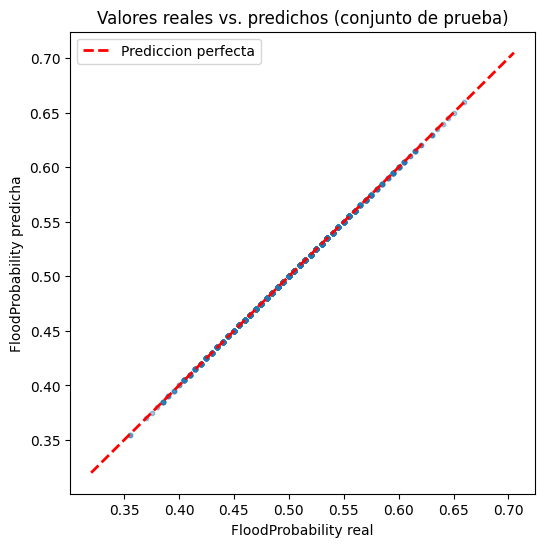

In [20]:
# Comparacion visual: valores reales vs. valores predichos (conjunto de prueba)
pyplot.figure(figsize=(6, 6))
muestra = np.random.choice(len(y_real_test), size=1000, replace=False)
pyplot.scatter(y_real_test[muestra], y_pred_test[muestra], alpha=0.4, s=10)
lims = [min(y_real_test.min(), y_pred_test.min()), max(y_real_test.max(), y_pred_test.max())]
pyplot.plot(lims, lims, 'r--', lw=2, label='Prediccion perfecta')
pyplot.xlabel('FloodProbability real')
pyplot.ylabel('FloodProbability predicha')
pyplot.title('Valores reales vs. predichos (conjunto de prueba)')
pyplot.legend()
pyplot.show()

## Inferencia con nuevos datos

Con el modelo entrenado y los valores `mu`, `sigma` calculados en el entrenamiento, se puede realizar inferencia sobre nuevos ejemplos. Es indispensable normalizar el nuevo ejemplo con la **misma** `mu` y `sigma` antes de pasarlo por el modelo.

In [21]:
def inferir_flood_probability(modelo, valores_caracteristicas, mu, sigma):
    '''
    Recibe una lista/array con los 20 valores de las caracteristicas (en el mismo orden que las
    columnas del dataset) y retorna la probabilidad de inundacion estimada por el modelo.
    '''
    x = np.array(valores_caracteristicas, dtype=float)
    x_norm = (x - mu) / sigma
    x_tensor = torch.tensor(x_norm, dtype=torch.float32).view(1, -1).to(device)

    modelo.eval()
    with torch.no_grad():
        pred = modelo(x_tensor)
    return pred.item()



ejemplo = X_test[0]
prediccion = inferir_flood_probability(modelo_cargado, ejemplo, mu, sigma)
valor_real = y_test[0]

print('Caracteristicas del ejemplo:')
print(dict(zip(X_df.columns, ejemplo)))
print(f'\nProbabilidad de inundacion predicha: {prediccion:.4f}')
print(f'Probabilidad de inundacion real:     {valor_real:.4f}')

Caracteristicas del ejemplo:
{'MonsoonIntensity': np.float64(6.0), 'TopographyDrainage': np.float64(8.0), 'RiverManagement': np.float64(1.0), 'Deforestation': np.float64(2.0), 'Urbanization': np.float64(5.0), 'ClimateChange': np.float64(3.0), 'DamsQuality': np.float64(4.0), 'Siltation': np.float64(7.0), 'AgriculturalPractices': np.float64(7.0), 'Encroachments': np.float64(9.0), 'IneffectiveDisasterPreparedness': np.float64(4.0), 'DrainageSystems': np.float64(5.0), 'CoastalVulnerability': np.float64(5.0), 'Landslides': np.float64(7.0), 'Watersheds': np.float64(4.0), 'DeterioratingInfrastructure': np.float64(4.0), 'PopulationScore': np.float64(6.0), 'WetlandLoss': np.float64(3.0), 'InadequatePlanning': np.float64(3.0), 'PoliticalFactors': np.float64(4.0)}

Probabilidad de inundacion predicha: 0.4850
Probabilidad de inundacion real:     0.4850


## Conclusiones

- Se adecuo el dataset **Flood Prediction Dataset** de Kaggle (20 caracteristicas, 50000 ejemplos) para entrenar un modelo de regresion lineal multivariable, reutilizando el mismo preprocesamiento con **Pandas** (revision de nulos, duplicados, separacion de `X` e `y`) y la misma normalizacion (`featureNormalize`) del Laboratorio 2.
- El manejo de los datos ya no se hace con arreglos `numpy` recorridos manualmente, sino con un objeto `Dataset` personalizado (`DatasetFlood`) y dos objetos `DataLoader` (entrenamiento y prueba) que iteran los datos en *batches* y mezclan el conjunto de entrenamiento en cada epoca.
- El modelo (equivalente al vector `theta`) se define como una capa `nn.Linear(20, 1)` dentro de una clase `nn.Module`.
- El costo (`computeCostMulti`) se reemplaza por el objeto `nn.MSELoss`, y la actualizacion manual de `theta` se reemplaza por el objeto optimizador `torch.optim.SGD`, cuyas derivadas se calculan automaticamente con `autograd` (`loss.backward()`).
- Se repitio el mismo analisis de seleccion de `alpha` que en el Laboratorio 2, ahora entrenando el modelo unas pocas epocas con cada valor de `lr` para elegir el que converge mas rapido sin divergir.
- Los pesos del modelo entrenado se guardaron con `torch.save` y se recargaron con `torch.load` para verificar que las predicciones se mantienen.
- El modelo se evaluo sobre un conjunto de prueba independiente (20% de los datos) usando MSE, RMSE y R^2 de `sklearn.metrics`, obteniendo resultados equivalentes a los del descenso por el gradiente manual del Laboratorio 2, lo que confirma que ambos enfoques resuelven el mismo problema de optimizacion: la diferencia esta en que `PyTorch` automatiza el manejo de datos, el calculo de derivadas y la actualizacion de parametros mediante sus objetos internos.
- Finalmente se implemento una funcion de inferencia (`inferir_flood_probability`) que utiliza el modelo de `PyTorch` para estimar la probabilidad de inundacion de un nuevo conjunto de 20 caracteristicas.